# Iris Flower Classification
### Task 1 — Multi-Class Benchmark Classification Pipeline

**Objective:** Classify Iris flowers into *setosa*, *versicolor*, and *virginica* using Logistic Regression and Decision Tree, then compare their performance.

**Required workflow**
- Load and inspect the CSV using Pandas
- Explore feature relationships with a Seaborn pairplot
- Split the data into 80% training and 20% testing data
- Standardize features using `StandardScaler` (fit on training data only)
- Train Logistic Regression and Decision Tree classifiers
- Compare accuracy, weighted precision, weighted recall, and weighted F1-score
- Plot confusion-matrix heatmaps and two-dimensional decision boundaries

**Dataset:** `iris.csv.

## 1. Import libraries

In [1]:


import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

from matplotlib.colors import ListedColormap


## 2. Load and inspect the dataset

In [2]:

df = pd.read_csv("iris.csv")

required_columns = [
    "sepal_length", "sepal_width", "petal_length", "petal_width", "species"
]
missing_columns = set(required_columns) - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)
print("\nMissing values per column:")
display(df.isnull().sum().to_frame("missing_values"))

print("\nSpecies counts:")
display(df["species"].value_counts().to_frame("count"))

print("\nNumerical summary:")
display(df.describe())


First five rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset shape: (150, 5)

Missing values per column:


,missing_values
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0



Species counts:


,count
species,
setosa,50
versicolor,50
virginica,50



Numerical summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 3. Exploratory data analysis — pairplot

E:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
E:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
E:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
E:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_

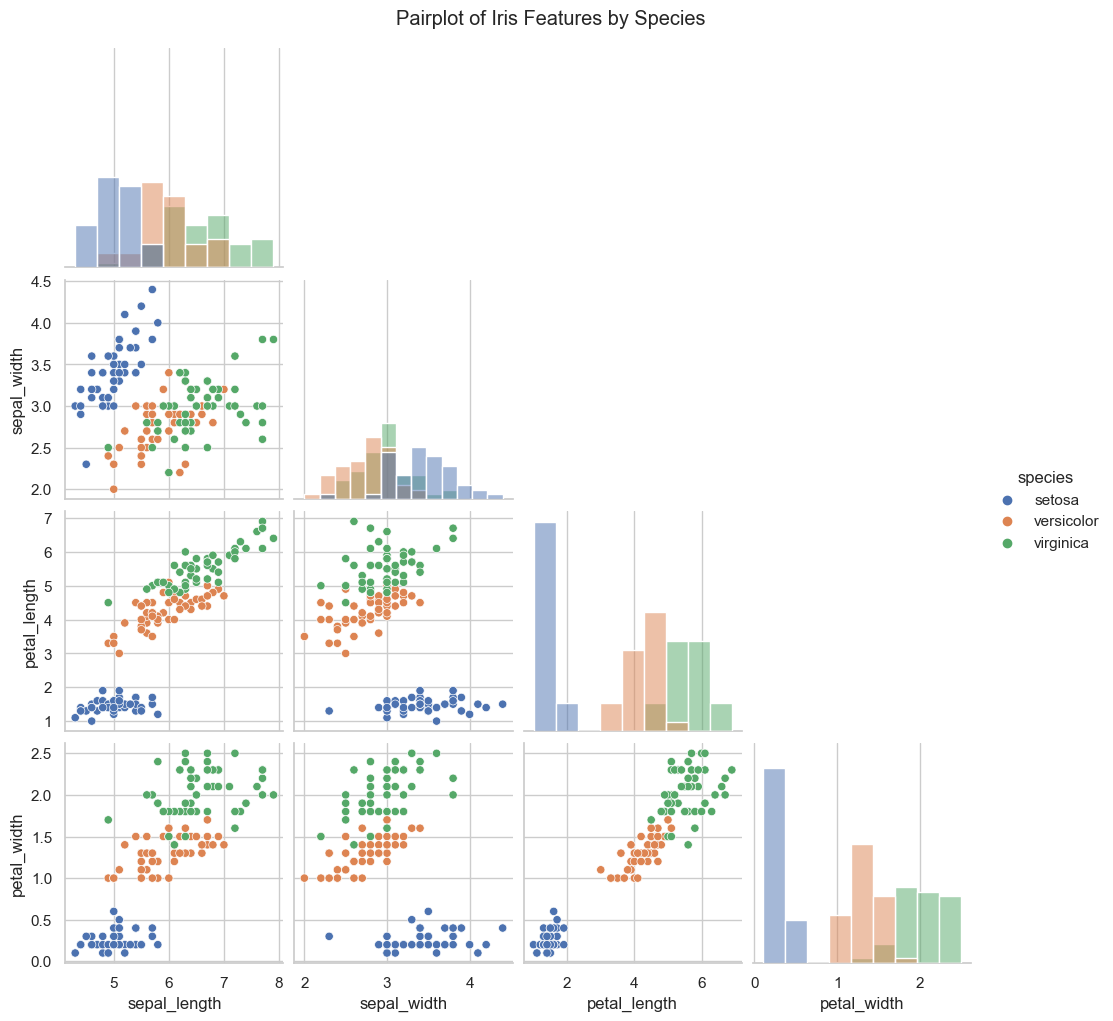

In [3]:
sns.pairplot(df, hue="species", diag_kind="hist", corner=True)
plt.suptitle("Pairplot of Iris Features by Species", y=1.02)
plt.show()


## 4. Prepare features and target

The four measurements are input features (`X`), and `species` is the target (`y`). The target labels are encoded as integers for consistent plotting and evaluation; the class names are retained for readable reports.

In [4]:
feature_columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = df[feature_columns].copy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df["species"])

class_names = label_encoder.classes_
print("Class labels:", {name: int(label_encoder.transform([name])[0]) for name in class_names})


Class labels: {'setosa': 0, 'versicolor': 1, 'virginica': 2}


## 5. Split the data (80/20)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training rows: {len(X_train)} ({len(X_train) / len(X):.0%})")
print(f"Testing rows:  {len(X_test)} ({len(X_test) / len(X):.0%})")


Training rows: 120 (80%)
Testing rows:  30 (20%)


## 6. Build and train the models

A `Pipeline` ensures scaling is learned from the training data only for Logistic Regression. A Decision Tree does not require scaling, but we also train it on the standardized features so the project uses a consistent preprocessing workflow. Tree predictions are generally unaffected by standardization.

In [6]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

decision_tree_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE))
])

logistic_model.fit(X_train, y_train)
decision_tree_model.fit(X_train, y_train)

lr_predictions = logistic_model.predict(X_test)
dt_predictions = decision_tree_model.predict(X_test)

print("Both models trained successfully.")


Both models trained successfully.


## 7. Evaluate and compare the models

In [7]:
predictions_by_model = {
    "Logistic Regression": lr_predictions,
    "Decision Tree": dt_predictions
}

rows = []
for model_name, predictions in predictions_by_model.items():
    rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (weighted)": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Recall (weighted)": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "F1-score (weighted)": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


### What the metrics mean

- **Accuracy:** proportion of test samples classified correctly.
- **Precision:** among predictions assigned to a class, how many were correct.
- **Recall:** among the actual samples of a class, how many were identified correctly.
- **F1-score:** harmonic mean of precision and recall.
- **Weighted average:** combines per-class scores while accounting for each class's number of test samples.



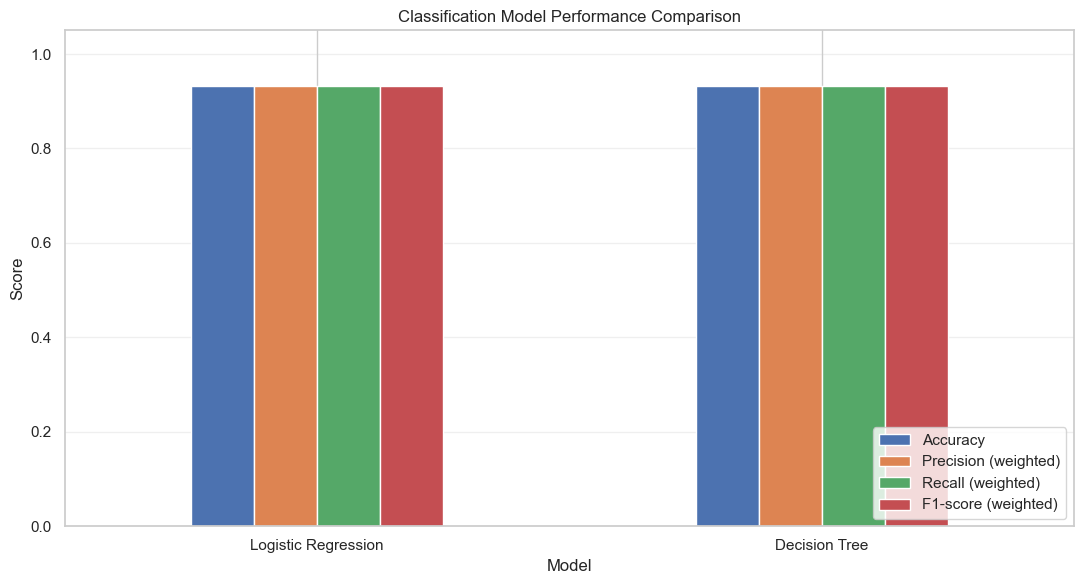

In [8]:
ax = results.plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))
ax.set_title("Classification Model Performance Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Classification reports

In [9]:
for model_name, predictions in predictions_by_model.items():
    print(f"\n{model_name} — classification report")
    print(classification_report(
        y_test,
        predictions,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))



Logistic Regression — classification report
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30


Decision Tree — classification report
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



## 9. Confusion matrix heatmaps

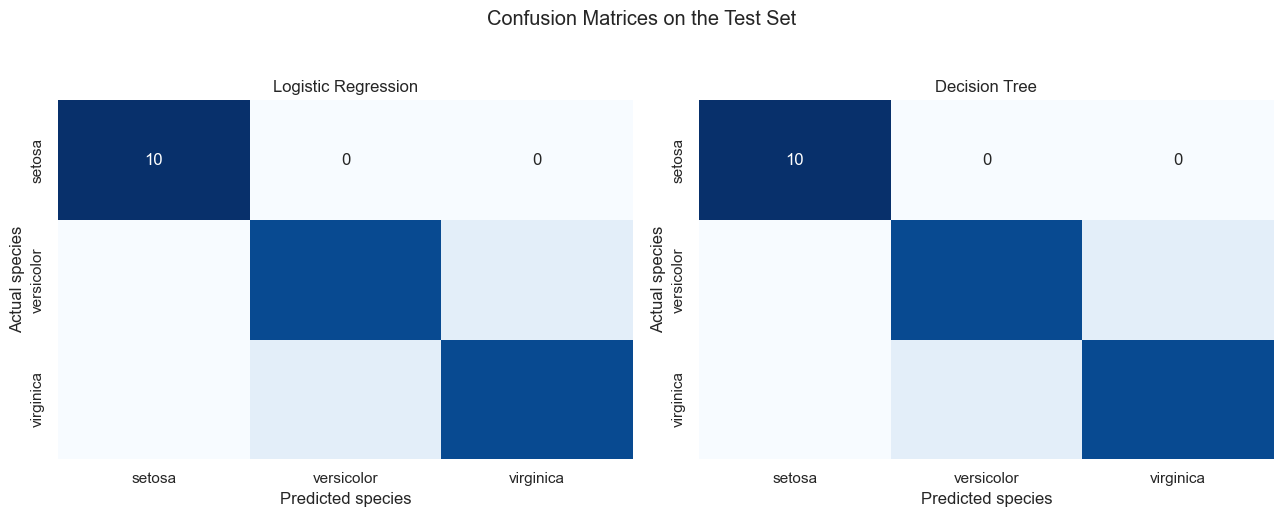

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (model_name, predictions) in zip(axes, predictions_by_model.items()):
    cm = confusion_matrix(
        y_test, predictions, labels=np.arange(len(class_names))
    )
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=class_names, yticklabels=class_names, ax=ax
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted species")
    ax.set_ylabel("Actual species")

fig.suptitle("Confusion Matrices on the Test Set", y=1.03)
plt.tight_layout()
plt.show()


**Interpretation:** Rows show actual classes and columns show predicted classes. The diagonal cells count correct predictions; off-diagonal cells show misclassifications.

## 10. Decision Tree visualization

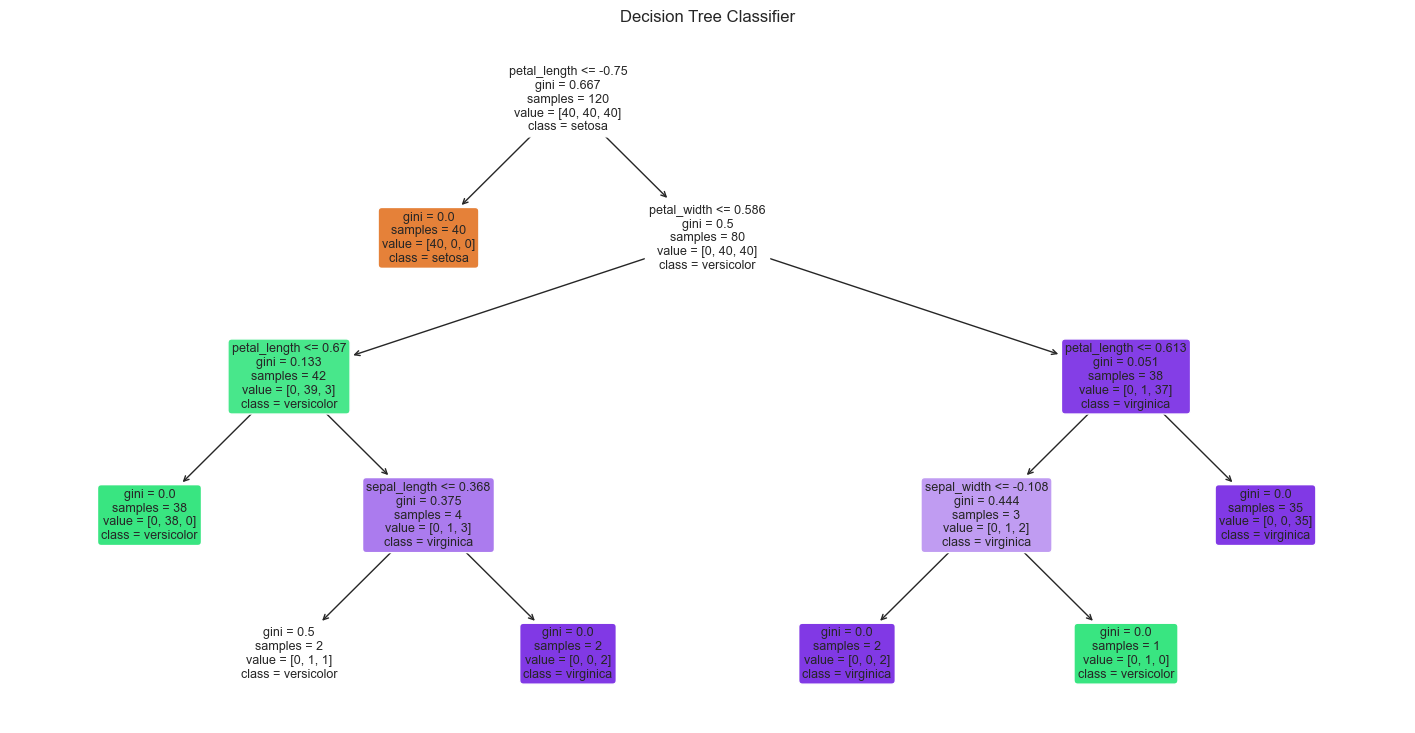

In [11]:
tree_classifier = decision_tree_model.named_steps["classifier"]

plt.figure(figsize=(18, 9))
plot_tree(
    tree_classifier,
    feature_names=feature_columns,
    class_names=class_names,
    filled=True,
    rounded=True,
    proportion=False,
    fontsize=9
)
plt.title("Decision Tree Classifier")
plt.show()


## 11. Decision boundary visualization

A standard decision boundary plot is two-dimensional, so it uses **petal length** and **petal width** only. These two-feature models are trained specifically for visualization and are separate from the four-feature models used for the main evaluation.

E:\Anaconda\Lib\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
E:\Anaconda\Lib\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


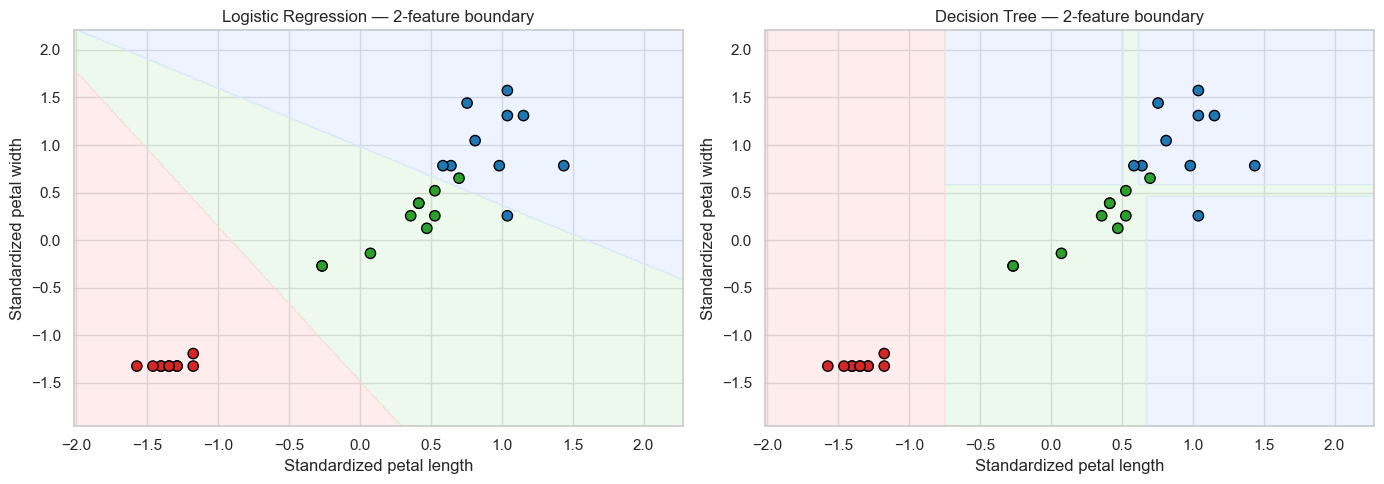

In [12]:
boundary_features = ["petal_length", "petal_width"]
X_2d = df[boundary_features]
y_2d = label_encoder.transform(df["species"])

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y_2d,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_2d
)

lr_2d = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
dt_2d = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE))
])

lr_2d.fit(X_train_2d, y_train_2d)
dt_2d.fit(X_train_2d, y_train_2d)

# Use each pipeline's scaler to create a grid in standardized coordinates.
scaler_2d = lr_2d.named_steps["scaler"]
X_train_2d_scaled = scaler_2d.transform(X_train_2d)

x_min, x_max = X_train_2d_scaled[:, 0].min() - 0.5, X_train_2d_scaled[:, 0].max() + 0.5
y_min, y_max = X_train_2d_scaled[:, 1].min() - 0.5, X_train_2d_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)
grid_scaled = np.c_[xx.ravel(), yy.ravel()]

# Convert grid points back to original feature units because Pipeline.predict
# expects unscaled input and scales it internally.
grid_original = scaler_2d.inverse_transform(grid_scaled)

background_cmap = ListedColormap(["#ffd6d6", "#d9f2d9", "#d9e6ff"])
point_cmap = ListedColormap(["#d62728", "#2ca02c", "#1f77b4"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in [
    (axes[0], lr_2d, "Logistic Regression"),
    (axes[1], dt_2d, "Decision Tree")
]:
    Z = model.predict(grid_original).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.45, cmap=background_cmap)

    # Plot held-out points in standardized feature coordinates.
    X_test_scaled = scaler_2d.transform(X_test_2d)
    ax.scatter(
        X_test_scaled[:, 0], X_test_scaled[:, 1],
        c=y_test_2d, cmap=point_cmap, edgecolor="black", s=55
    )
    ax.set_title(f"{title} — 2-feature boundary")
    ax.set_xlabel("Standardized petal length")
    ax.set_ylabel("Standardized petal width")

plt.tight_layout()
plt.show()


## 12. Test a prediction on a new flower

In [13]:
# Example measurements: sepal length, sepal width, petal length, petal width
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=feature_columns
)

predicted_label = logistic_model.predict(new_flower)[0]
predicted_species = label_encoder.inverse_transform([predicted_label])[0]

print("New flower measurements:")
display(new_flower)
print("Predicted species:", predicted_species)


New flower measurements:


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2


Predicted species: setosa


## 13. Conclusion

This project used the Iris dataset to build and compare Logistic Regression and Decision Tree classifiers. The data was explored using a pairplot, split into training and test sets using an 80:20 ratio, and evaluated using accuracy, weighted precision, weighted recall, weighted F1-score, classification reports, and confusion matrices. A two-feature decision-boundary visualization was also created using petal length and petal width.
